In [1]:
from huggingface_hub import snapshot_download

path = snapshot_download(
    repo_id="OneScience-Group/cfd_benchmark",
    repo_type="dataset",
    local_dir="/kaggle/working/cfd_benchmark",
    allow_patterns=["data/elasticity/*"]
    # allow_patterns=["data/airfoil/*"]
# allow_patterns=["data/darcy/*"]
# allow_patterns=["data/elasticity/*"]
# allow_patterns=["data/ns/*"]
# allow_patterns=["data/pipe/*"]
# allow_patterns=["data/plas/*"]
)

import numpy as np
import matplotlib.pyplot as plt


Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

In [3]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


## 1. Hyperparameters

In [4]:
HPARAMS = {
    # data
    "xy_path": "/kaggle/working/cfd_benchmark/data/elasticity/Meshes/Random_UnitCell_XY_10.npy",
    "stress_path": "/kaggle/working/cfd_benchmark/data/elasticity/Meshes/Random_UnitCell_sigma_10.npy",
    "n_train": 1000,
    "n_test": 200,

    # model
    "condition_dim": 2,
    "solution_init_dim": None,
    "out_dim": 1,
    "hidden_dim": 128,
    "core_layers": 2,
    "n_heads": 8,
    "slice_num": 64,
    "mlp_ratio": 1,
    "dropout": 0.0,
    "act": "gelu",
    "norm_eps": 1e-5,

    # recursion
    "L_cycles": 3,
    "H_cycles": 3,
    "supervision_steps": 2,
    "truncate_early_cycles": True,

    # training
    "batch_size": 32,
    "epochs": 500,
    "lr": 1e-3,
    "weight_decay": 1e-5,
    "max_grad_norm": 0.1,

    # runtime
    "num_workers": 0,
    "pin_memory": True,
    "seed": 42,

    # output
    "checkpoint_path": "/kaggle/working/trttransolver_elasticity_trmnorm.pt",
    "debug_csv_path": "/kaggle/working/trttransolver_trmnorm_debug_log.csv",
}

DEBUG = {
    "stop_on_nonfinite": True,
    "log_every_n_batches": 20,
    "print_every_n_batches": 20,
    "max_train_batches": None,   # e.g. 100 for a quick debug run
    "max_test_batches": None,
    "detect_anomaly": False,
    "save_parameter_snapshots": True,
}

torch.autograd.set_detect_anomaly(DEBUG["detect_anomaly"])


## 2. Diagnostics and RMSNorm

In [5]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def rms_norm(x, eps=1e-5):
    # ============================================================
    # FIX A/B helper:
    # TRM-style RMS normalization in float32 for numerical safety.
    # ============================================================
    dtype = x.dtype
    xf = x.float()
    variance = xf.square().mean(dim=-1, keepdim=True)
    xf = xf * torch.rsqrt(variance + eps)
    return xf.to(dtype)


def tensor_stats(x):
    x = x.detach()
    finite = torch.isfinite(x)

    out = {
        "finite_fraction": finite.float().mean().item(),
        "nan_count": torch.isnan(x).sum().item(),
        "inf_count": torch.isinf(x).sum().item(),
    }

    if finite.any():
        xf = x[finite].float()
        out.update({
            "mean": xf.mean().item(),
            "std": xf.std(unbiased=False).item(),
            "rms": torch.sqrt(torch.mean(xf * xf)).item(),
            "absmax": xf.abs().max().item(),
            "norm": xf.norm().item(),
            "min": xf.min().item(),
            "max": xf.max().item(),
        })
    else:
        out.update({
            "mean": np.nan, "std": np.nan, "rms": np.nan,
            "absmax": np.nan, "norm": np.nan,
            "min": np.nan, "max": np.nan,
        })

    return out


def check_finite(name, x, context=None):
    if torch.isfinite(x).all():
        return

    context = context or {}
    print("\n" + "=" * 90)
    print("NON-FINITE TENSOR:", name)
    print("context:", context)
    print("shape:", tuple(x.shape))
    print("stats:", tensor_stats(x))
    print("=" * 90)

    if DEBUG["stop_on_nonfinite"]:
        raise FloatingPointError(f"{name} contains NaN/Inf at {context}")


def flatten_finite_tensors(tensors):
    vals = []
    for t in tensors:
        if t is None:
            continue
        a = t.detach().float().reshape(-1).cpu()
        a = a[torch.isfinite(a)]
        if a.numel():
            vals.append(a)
    return torch.cat(vals) if vals else torch.empty(0)


def parameter_group_map(model):
    return {
        "condition_encoder": list(model.condition_encoder.parameters()),
        "core": list(model.core.parameters()),
        "decoder": list(model.solution_decoder.parameters()),
    }


def stats_from_flat(flat):
    if flat.numel() == 0:
        return {
            "mean": np.nan, "std": np.nan, "rms": np.nan,
            "absmax": np.nan, "norm": np.nan,
        }
    return {
        "mean": flat.mean().item(),
        "std": flat.std(unbiased=False).item(),
        "rms": torch.sqrt(torch.mean(flat * flat)).item(),
        "absmax": flat.abs().max().item(),
        "norm": flat.norm().item(),
    }


def group_parameter_stats(params):
    return stats_from_flat(
        flatten_finite_tensors([p.data for p in params])
    )


def group_gradient_stats(params):
    return stats_from_flat(
        flatten_finite_tensors([p.grad for p in params if p.grad is not None])
    )


def snapshot_parameter_values(model):
    return {
        name: flatten_finite_tensors([p.data for p in params]).numpy()
        for name, params in parameter_group_map(model).items()
    }


def snapshot_gradient_values(model):
    return {
        name: flatten_finite_tensors(
            [p.grad for p in params if p.grad is not None]
        ).numpy()
        for name, params in parameter_group_map(model).items()
    }


set_seed(HPARAMS["seed"])


## 3. Elasticity dataset

In [6]:
def load_elasticity_data(xy_path, stress_path):
    xy = torch.from_numpy(np.load(xy_path)).float().permute(2, 0, 1).contiguous()
    stress = torch.from_numpy(np.load(stress_path)).float().permute(1, 0).contiguous()

    if xy.shape[0] != stress.shape[0] or xy.shape[1] != stress.shape[1]:
        raise ValueError(
            f"Incompatible shapes: xy={tuple(xy.shape)}, stress={tuple(stress.shape)}"
        )

    return xy, stress


class OutputNormalizer:
    def __init__(self, mean, std):
        self.mean = torch.as_tensor(mean, dtype=torch.float32)
        self.std = torch.as_tensor(std, dtype=torch.float32)

    @classmethod
    def fit(cls, y_train, eps=1e-8):
        return cls(y_train.mean(), y_train.std() + eps)

    def encode(self, y):
        mean = self.mean.to(y.device, y.dtype)
        std = self.std.to(y.device, y.dtype)
        return (y - mean) / std

    def decode(self, y):
        mean = self.mean.to(y.device, y.dtype)
        std = self.std.to(y.device, y.dtype)
        return y * std + mean

    def __repr__(self):
        return (
            f"OutputNormalizer(mean={self.mean.item():.6f}, "
            f"std={self.std.item():.6f})"
        )


class ElasticityDataset(Dataset):
    def __init__(self, xy, stress, indices, output_normalizer, normalize_output):
        self.xy = xy
        self.stress = stress
        self.indices = torch.as_tensor(indices, dtype=torch.long)
        self.output_normalizer = output_normalizer
        self.normalize_output = normalize_output

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = self.indices[i]
        x = self.xy[idx]
        y = self.stress[idx].unsqueeze(-1)

        if self.normalize_output:
            y = self.output_normalizer.encode(y)

        return x, y


xy, stress = load_elasticity_data(
    HPARAMS["xy_path"],
    HPARAMS["stress_path"],
)

n_samples = len(xy)
train_idx = torch.arange(HPARAMS["n_train"])
test_idx = torch.arange(n_samples - HPARAMS["n_test"], n_samples)

normalizer = OutputNormalizer.fit(stress[train_idx])

train_dataset = ElasticityDataset(
    xy, stress, train_idx, normalizer, normalize_output=True
)
test_dataset = ElasticityDataset(
    xy, stress, test_idx, normalizer, normalize_output=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=HPARAMS["batch_size"],
    shuffle=True,
    num_workers=HPARAMS["num_workers"],
    pin_memory=HPARAMS["pin_memory"],
)

test_loader = DataLoader(
    test_dataset,
    batch_size=HPARAMS["batch_size"],
    shuffle=False,
    num_workers=HPARAMS["num_workers"],
    pin_memory=HPARAMS["pin_memory"],
)

print("XY:", tuple(xy.shape))
print("Stress:", tuple(stress.shape))
print("Train samples:", len(train_dataset))
print("Test samples:", len(test_dataset))
print(normalizer)


XY: (2000, 972, 2)
Stress: (2000, 972)
Train samples: 1000
Test samples: 200
OutputNormalizer(mean=187.738739, std=127.082878)


## 4. Debug recorder

In [7]:
class DebugRecorder:
    def __init__(self):
        self.rows = []

    def record_tensor(self, tag, x, context):
        row = dict(context)
        row.update({"kind": "tensor", "tag": tag, **tensor_stats(x)})
        self.rows.append(row)

    def record_scalar(self, tag, value, context):
        row = dict(context)
        row.update({"kind": "scalar", "tag": tag, "value": float(value)})
        self.rows.append(row)

    def dataframe(self):
        return pd.DataFrame(self.rows)


recorder = DebugRecorder()


## 5. Corrected TrTtransolver

In [8]:
class MLP(nn.Module):
    def __init__(self, n_input, n_hidden, n_output, n_layers=1, act="gelu", res=True):
        super().__init__()
        activations = {
            "gelu": nn.GELU,
            "relu": nn.ReLU,
            "silu": nn.SiLU,
            "tanh": nn.Tanh,
            "elu": nn.ELU,
        }
        Act = activations[act]
        self.res = res

        self.linear_pre = nn.Sequential(
            nn.Linear(n_input, n_hidden),
            Act(),
        )
        self.linears = nn.ModuleList([
            nn.Sequential(nn.Linear(n_hidden, n_hidden), Act())
            for _ in range(n_layers)
        ])
        self.linear_post = nn.Linear(n_hidden, n_output)

    def forward(self, x):
        x = self.linear_pre(x)
        for layer in self.linears:
            x = x + layer(x) if self.res else layer(x)
        return self.linear_post(x)


class PhysicsAttentionIrregularMesh(nn.Module):
    def __init__(self, dim, heads, dim_head, slice_num, dropout):
        super().__init__()

        inner_dim = heads * dim_head
        self.heads = heads
        self.dim_head = dim_head
        self.scale = dim_head ** -0.5

        self.softmax = nn.Softmax(dim=-1)
        self.dropout = nn.Dropout(dropout)

        self.temperature = nn.Parameter(
            torch.ones(1, heads, 1, 1) * 0.5
        )

        self.in_project_x = nn.Linear(dim, inner_dim)
        self.in_project_fx = nn.Linear(dim, inner_dim)
        self.in_project_slice = nn.Linear(dim_head, slice_num)

        self.to_q = nn.Linear(dim_head, dim_head, bias=False)
        self.to_k = nn.Linear(dim_head, dim_head, bias=False)
        self.to_v = nn.Linear(dim_head, dim_head, bias=False)

        self.to_out = nn.Sequential(
            nn.Linear(inner_dim, dim),
            nn.Dropout(dropout),
        )

    def forward(self, x, debug=None, context=None):
        B, N, _ = x.shape
        context = context or {}

        check_finite("physics_attention.input", x, context)

        x_mid = self.in_project_x(x)
        fx_mid = self.in_project_fx(x)

        x_mid = x_mid.reshape(
            B, N, self.heads, self.dim_head
        ).permute(0, 2, 1, 3).contiguous()

        fx_mid = fx_mid.reshape(
            B, N, self.heads, self.dim_head
        ).permute(0, 2, 1, 3).contiguous()

        check_finite("x_mid", x_mid, context)
        check_finite("fx_mid", fx_mid, context)
        check_finite("temperature", self.temperature, context)

        slice_logits = self.in_project_slice(x_mid) / self.temperature
        check_finite("slice_logits", slice_logits, context)

        slice_weights = self.softmax(slice_logits)
        check_finite("slice_weights", slice_weights, context)

        slice_norm = slice_weights.sum(dim=2)
        check_finite("slice_norm", slice_norm, context)

        slice_tokens = torch.einsum(
            "bhnd,bhnm->bhmd",
            fx_mid,
            slice_weights,
        )
        slice_tokens = slice_tokens / (
            slice_norm.unsqueeze(-1) + 1e-5
        )
        check_finite("slice_tokens", slice_tokens, context)

        q = self.to_q(slice_tokens)
        k = self.to_k(slice_tokens)
        v = self.to_v(slice_tokens)

        attention_logits = (
            torch.matmul(q, k.transpose(-1, -2))
            * self.scale
        )
        check_finite("attention_logits", attention_logits, context)

        attention = self.softmax(attention_logits)
        attention = self.dropout(attention)
        check_finite("attention", attention, context)

        out_slice = torch.matmul(attention, v)

        out = torch.einsum(
            "bhmd,bhnm->bhnd",
            out_slice,
            slice_weights,
        )
        out = out.permute(0, 2, 1, 3).contiguous()
        out = out.reshape(B, N, self.heads * self.dim_head)
        out = self.to_out(out)

        check_finite("physics_attention.output", out, context)

        if debug is not None:
            entropy = -(
                slice_weights.clamp_min(1e-12)
                * slice_weights.clamp_min(1e-12).log()
            ).sum(dim=-1).mean()

            debug.record_scalar(
                "temperature_min",
                self.temperature.detach().min().item(),
                context,
            )
            debug.record_scalar(
                "temperature_max",
                self.temperature.detach().max().item(),
                context,
            )
            debug.record_scalar(
                "temperature_absmin",
                self.temperature.detach().abs().min().item(),
                context,
            )
            debug.record_scalar(
                "slice_logits_absmax",
                slice_logits.detach().abs().max().item(),
                context,
            )
            debug.record_scalar(
                "slice_norm_min",
                slice_norm.detach().min().item(),
                context,
            )
            debug.record_scalar(
                "slice_norm_max",
                slice_norm.detach().max().item(),
                context,
            )
            debug.record_scalar(
                "slice_entropy",
                entropy.detach().item(),
                context,
            )
            debug.record_scalar(
                "attention_logits_absmax",
                attention_logits.detach().abs().max().item(),
                context,
            )

        return out


class TRMNormalizedTransolverBlock(nn.Module):
    # ============================================================
    # FIX A + FIX B:
    #
    # TRM-style post-residual normalization:
    #
    #   x = RMSNorm(x + PhysicsAttention(x))
    #   x = RMSNorm(x + FFN(x))
    #
    # Note: there is NO pre-LayerNorm here.
    # ============================================================

    def __init__(
        self,
        hidden_dim,
        n_heads,
        slice_num,
        mlp_ratio,
        dropout,
        act,
        norm_eps,
    ):
        super().__init__()

        if hidden_dim % n_heads != 0:
            raise ValueError("hidden_dim must be divisible by n_heads")

        self.norm_eps = norm_eps

        self.attn = PhysicsAttentionIrregularMesh(
            dim=hidden_dim,
            heads=n_heads,
            dim_head=hidden_dim // n_heads,
            slice_num=slice_num,
            dropout=dropout,
        )

        self.mlp = MLP(
            n_input=hidden_dim,
            n_hidden=hidden_dim * mlp_ratio,
            n_output=hidden_dim,
            n_layers=0,
            act=act,
            res=False,
        )

    def forward(self, x, debug=None, context=None):
        context = context or {}

        attn_out = self.attn(
            x,
            debug=debug,
            context=context,
        )

        # ---------------- FIX A ----------------
        x = rms_norm(
            x + attn_out,
            eps=self.norm_eps,
        )

        check_finite(
            "block.after_attention_rmsnorm",
            x,
            context,
        )

        if debug is not None:
            debug.record_tensor(
                "block_after_attention_rmsnorm",
                x,
                context,
            )

        mlp_out = self.mlp(x)

        # ---------------- FIX B ----------------
        x = rms_norm(
            x + mlp_out,
            eps=self.norm_eps,
        )

        check_finite(
            "block.after_mlp_rmsnorm",
            x,
            context,
        )

        if debug is not None:
            debug.record_tensor(
                "block_after_mlp_rmsnorm",
                x,
                context,
            )

        return x


class TinyTransolverCore(nn.Module):
    def __init__(
        self,
        hidden_dim,
        core_layers,
        n_heads,
        slice_num,
        mlp_ratio,
        dropout,
        act,
        norm_eps,
    ):
        super().__init__()

        self.blocks = nn.ModuleList([
            TRMNormalizedTransolverBlock(
                hidden_dim=hidden_dim,
                n_heads=n_heads,
                slice_num=slice_num,
                mlp_ratio=mlp_ratio,
                dropout=dropout,
                act=act,
                norm_eps=norm_eps,
            )
            for _ in range(core_layers)
        ])

    def forward(self, x, debug=None, context=None):
        for block_idx, block in enumerate(self.blocks):
            block_context = dict(context or {})
            block_context["core_block"] = block_idx

            x = block(
                x,
                debug=debug,
                context=block_context,
            )

            if debug is not None:
                debug.record_tensor(
                    f"core_block_{block_idx}_output",
                    x,
                    block_context,
                )

        return x


class TrTtransolver(nn.Module):
    def __init__(
        self,
        condition_dim,
        solution_init_dim,
        out_dim,
        hidden_dim,
        core_layers,
        n_heads,
        slice_num,
        mlp_ratio,
        dropout,
        act,
        norm_eps,
        L_cycles,
        H_cycles,
    ):
        super().__init__()

        self.hidden_dim = hidden_dim
        self.L_cycles = L_cycles
        self.H_cycles = H_cycles

        self.condition_encoder = MLP(
            condition_dim,
            2 * hidden_dim,
            hidden_dim,
            n_layers=0,
            act=act,
            res=False,
        )

        if solution_init_dim is not None:
            self.solution_encoder = MLP(
                solution_init_dim,
                2 * hidden_dim,
                hidden_dim,
                n_layers=0,
                act=act,
                res=False,
            )
        else:
            self.solution_encoder = None

        # ============================================================
        # FIX D:
        # Fixed random initial states, stored as buffers.
        # They are NOT optimized.
        # ============================================================
        y0 = torch.empty(1, 1, hidden_dim)
        z0 = torch.empty(1, 1, hidden_dim)

        nn.init.trunc_normal_(y0, mean=0.0, std=1.0, a=-2.0, b=2.0)
        nn.init.trunc_normal_(z0, mean=0.0, std=1.0, a=-2.0, b=2.0)

        self.register_buffer("y_init", y0, persistent=True)
        self.register_buffer("z_init", z0, persistent=True)

        self.core = TinyTransolverCore(
            hidden_dim=hidden_dim,
            core_layers=core_layers,
            n_heads=n_heads,
            slice_num=slice_num,
            mlp_ratio=mlp_ratio,
            dropout=dropout,
            act=act,
            norm_eps=norm_eps,
        )

        self.solution_decoder = nn.Linear(
            hidden_dim,
            out_dim,
        )

        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, nn.Linear):
            nn.init.trunc_normal_(module.weight, std=0.02)
            if module.bias is not None:
                nn.init.constant_(module.bias, 0.0)

    def encode_condition(self, condition):
        return self.condition_encoder(condition)

    def initialize_states(self, x, initial_solution=None):
        B, N, _ = x.shape

        if initial_solution is not None:
            if self.solution_encoder is None:
                raise ValueError(
                    "initial_solution provided but solution_init_dim=None"
                )
            y = self.solution_encoder(initial_solution)
        else:
            y = self.y_init.expand(B, N, -1)

        z = self.z_init.expand(B, N, -1)

        return y, z

    def reasoning_cycle(
        self,
        x,
        y,
        z,
        debug=None,
        base_context=None,
        h_cycle=None,
    ):
        base_context = dict(base_context or {})

        for l_cycle in range(self.L_cycles):
            context = dict(base_context)
            context.update({
                "h_cycle": h_cycle,
                "l_cycle": l_cycle,
                "update": "z",
            })

            core_input = x + y + z

            if debug is not None:
                debug.record_tensor(
                    "z_core_input",
                    core_input,
                    context,
                )

            z = self.core(
                core_input,
                debug=debug,
                context=context,
            )

            # ========================================================
            # FIX C:
            # No outer RMSNorm here.
            # The final block in self.core has already RMS-normalized z.
            # ========================================================

            check_finite("z_state", z, context)

            if debug is not None:
                debug.record_tensor(
                    "z_state",
                    z,
                    context,
                )

        context = dict(base_context)
        context.update({
            "h_cycle": h_cycle,
            "l_cycle": self.L_cycles,
            "update": "y",
        })

        y = self.core(
            y + z,
            debug=debug,
            context=context,
        )

        # FIX C again: no extra normalization here.

        check_finite("y_state", y, context)

        if debug is not None:
            debug.record_tensor(
                "y_state",
                y,
                context,
            )

        return y, z

    def forward(
        self,
        condition,
        initial_solution=None,
        y=None,
        z=None,
        truncate_early_cycles=True,
        debug=None,
        base_context=None,
    ):
        base_context = dict(base_context or {})

        x = self.encode_condition(condition)
        check_finite("condition_encoding_x", x, base_context)

        if debug is not None:
            debug.record_tensor(
                "condition_encoding_x",
                x,
                base_context,
            )

        if (y is None) != (z is None):
            raise ValueError("Provide both y and z, or neither.")

        if y is None:
            y, z = self.initialize_states(
                x,
                initial_solution=initial_solution,
            )

        if truncate_early_cycles:
            with torch.no_grad():
                for h in range(self.H_cycles - 1):
                    y, z = self.reasoning_cycle(
                        x,
                        y,
                        z,
                        debug=debug,
                        base_context=base_context,
                        h_cycle=h,
                    )

            y, z = self.reasoning_cycle(
                x,
                y,
                z,
                debug=debug,
                base_context=base_context,
                h_cycle=self.H_cycles - 1,
            )
        else:
            for h in range(self.H_cycles):
                y, z = self.reasoning_cycle(
                    x,
                    y,
                    z,
                    debug=debug,
                    base_context=base_context,
                    h_cycle=h,
                )

        pred_norm = self.solution_decoder(y)

        check_finite("pred_norm", pred_norm, base_context)

        if debug is not None:
            debug.record_tensor("final_y", y, base_context)
            debug.record_tensor("final_z", z, base_context)
            debug.record_tensor("pred_norm", pred_norm, base_context)

        return pred_norm, y, z


## 6. Instantiate model

In [10]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = TrTtransolver(
    condition_dim=HPARAMS["condition_dim"],
    solution_init_dim=HPARAMS["solution_init_dim"],
    out_dim=HPARAMS["out_dim"],
    hidden_dim=HPARAMS["hidden_dim"],
    core_layers=HPARAMS["core_layers"],
    n_heads=HPARAMS["n_heads"],
    slice_num=HPARAMS["slice_num"],
    mlp_ratio=HPARAMS["mlp_ratio"],
    dropout=HPARAMS["dropout"],
    act=HPARAMS["act"],
    norm_eps=HPARAMS["norm_eps"],
    L_cycles=HPARAMS["L_cycles"],
    H_cycles=HPARAMS["H_cycles"],
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=HPARAMS["lr"],
    weight_decay=HPARAMS["weight_decay"],
)

# scheduler = 
# torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer,
#     T_max=HPARAMS["epochs"],
# )

n_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Device:", device)
print(f"Trainable parameters: {n_params:,}")
print("y_init requires_grad:", model.y_init.requires_grad)
print("z_init requires_grad:", model.z_init.requires_grad)
print("y_init stats:", tensor_stats(model.y_init))
print("z_init stats:", tensor_stats(model.z_init))

initial_parameter_snapshot = snapshot_parameter_values(model)

rows = []
for group_name, params in parameter_group_map(model).items():
    row = {"group": group_name}
    row.update(group_parameter_stats(params))
    rows.append(row)

display(pd.DataFrame(rows))


Device: cuda
Trainable parameters: 202,641
y_init requires_grad: False
z_init requires_grad: False
y_init stats: {'finite_fraction': 1.0, 'nan_count': 0, 'inf_count': 0, 'mean': 0.07559917867183685, 'std': 0.9422524571418762, 'rms': 0.9452803134918213, 'absmax': 1.9572780132293701, 'norm': 10.694625854492188, 'min': -1.926795244216919, 'max': 1.9572780132293701}
z_init stats: {'finite_fraction': 1.0, 'nan_count': 0, 'inf_count': 0, 'mean': -0.042201630771160126, 'std': 0.8726992607116699, 'rms': 0.8737190365791321, 'absmax': 1.853150486946106, 'norm': 9.885002136230469, 'min': -1.853150486946106, 'max': 1.807318925857544}


,group,mean,std,rms,absmax,norm
0,condition_encoder,-0.000192,0.019925,0.019926,0.094157,3.655991
1,core,-0.000007,0.020474,0.020474,0.500000,8.413179
2,decoder,0.000182,0.020337,0.020338,0.054525,0.230991


## 7. Loss and metric

In [11]:
def relative_l2_per_sample(pred, target):
    B = pred.shape[0]

    pred = pred.reshape(B, -1)
    target = target.reshape(B, -1)

    diff_norm = torch.norm(
        pred - target,
        p=2,
        dim=1,
    )

    target_norm = torch.norm(
        target,
        p=2,
        dim=1,
    )

    return diff_norm / target_norm


def relative_l2_loss(pred, target):
    return relative_l2_per_sample(
        pred,
        target,
    ).sum()


def mae_metric(pred, target):
    return torch.mean(
        torch.abs(pred - target)
    )


## 8. Dry run — inspect H/L state magnitudes before training

In [12]:
model.eval()

condition, target_norm = next(iter(train_loader))

condition = condition.to(device)
target_norm = target_norm.to(device)
target = normalizer.decode(target_norm)

dry_recorder = DebugRecorder()

with torch.no_grad():
    pred_norm, state_y, state_z = model(
        condition=condition,
        y=None,
        z=None,
        truncate_early_cycles=HPARAMS["truncate_early_cycles"],
        debug=dry_recorder,
        base_context={
            "epoch": -1,
            "batch": 0,
            "supervision": 0,
            "phase": "dry_run",
        },
    )

pred = normalizer.decode(pred_norm)

print("pred:", tensor_stats(pred))
print("final y:", tensor_stats(state_y))
print("final z:", tensor_stats(state_z))
print("Relative L2:", relative_l2_loss(pred, target).item())

dry_df = dry_recorder.dataframe()

state_rows = dry_df[
    (dry_df["kind"] == "tensor")
    & (dry_df["tag"].isin(["z_state", "y_state"]))
].copy()

display(
    state_rows[
        [
            "h_cycle",
            "l_cycle",
            "update",
            "tag",
            "mean",
            "std",
            "rms",
            "absmax",
            "norm",
        ]
    ]
)


pred: {'finite_fraction': 0.9999999403953552, 'nan_count': 0, 'inf_count': 0, 'mean': 210.9426727294922, 'std': 0.10127521306276321, 'rms': 210.94268798828125, 'absmax': 211.14996337890625, 'norm': 37202.54296875, 'min': 210.73532104492188, 'max': 211.14996337890625}
final y: {'finite_fraction': 0.9999999403953552, 'nan_count': 0, 'inf_count': 0, 'mean': 0.09737665951251984, 'std': 0.9952426552772522, 'rms': 0.9999950528144836, 'absmax': 2.3941078186035156, 'norm': 1995.312744140625, 'min': -2.1925623416900635, 'max': 2.3941078186035156}
final z: {'finite_fraction': 0.9999999403953552, 'nan_count': 0, 'inf_count': 0, 'mean': 0.09691639244556427, 'std': 0.9952875375747681, 'rms': 0.9999950528144836, 'absmax': 2.387969493865967, 'norm': 1995.312744140625, 'min': -2.192051887512207, 'max': 2.387969493865967}
Relative L2: 18.147907257080078


,h_cycle,l_cycle,update,tag,mean,std,rms,absmax,norm
24,0.0,0.0,z,z_state,0.033597,0.999430,0.999995,2.551087,1995.312622
48,0.0,1.0,z,z_state,0.066198,0.997801,0.999995,2.482254,1995.312500
72,0.0,2.0,z,z_state,0.078818,0.996884,0.999995,2.299351,1995.312500
95,0.0,3.0,y,y_state,0.083643,0.996491,0.999995,2.169564,1995.312500
119,1.0,0.0,z,z_state,0.085395,0.996342,0.999995,2.300240,1995.312500
143,1.0,1.0,z,z_state,0.088456,0.996075,0.999995,2.296839,1995.312500
167,1.0,2.0,z,z_state,0.089904,0.995945,0.999995,2.294196,1995.312500
190,1.0,3.0,y,y_state,0.090568,0.995885,0.999995,2.292675,1995.312500
214,2.0,0.0,z,z_state,0.093957,0.995571,0.999995,2.349504,1995.312622
238,2.0,1.0,z,z_state,0.095938,0.995382,0.999995,2.375467,1995.312622


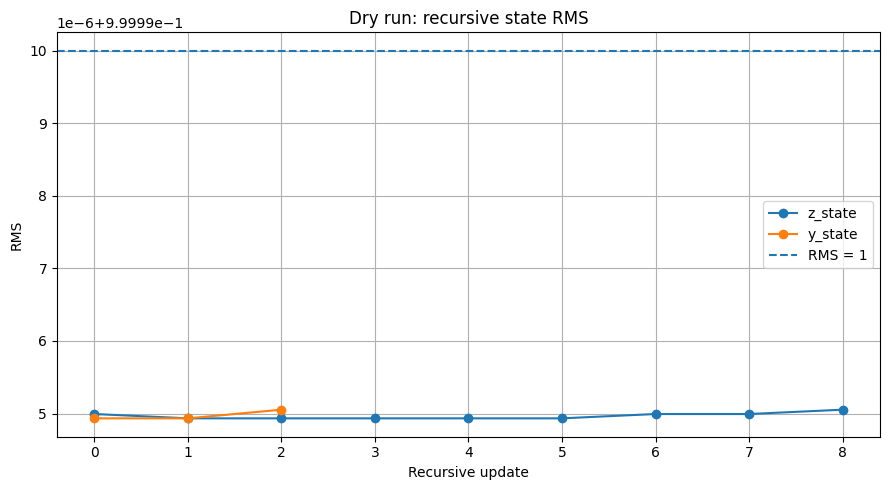

In [13]:
if len(state_rows):
    plt.figure(figsize=(9, 5))

    for tag in ["z_state", "y_state"]:
        d = state_rows[state_rows["tag"] == tag].reset_index(drop=True)

        if len(d):
            plt.plot(
                np.arange(len(d)),
                d["rms"],
                marker="o",
                label=tag,
            )

    plt.axhline(1.0, linestyle="--", label="RMS = 1")
    plt.xlabel("Recursive update")
    plt.ylabel("RMS")
    plt.title("Dry run: recursive state RMS")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


## 9. Training and evaluation with diagnostics

In [14]:
history = {
    "train_rel_l2": [],
    "test_rel_l2": [],
    "train_mae": [],
    "test_mae": [],
    "lr": [],
}

step_log = []
last_gradient_snapshot = None


def current_temperature_stats(model):
    temps = [
        m.temperature.detach().float().reshape(-1)
        for m in model.modules()
        if isinstance(m, PhysicsAttentionIrregularMesh)
    ]

    if not temps:
        return np.nan, np.nan, np.nan

    t = torch.cat(temps)

    return (
        t.min().item(),
        t.max().item(),
        t.abs().min().item(),
    )


def add_group_stats(model, row):
    for group_name, params in parameter_group_map(model).items():
        ps = group_parameter_stats(params)
        gs = group_gradient_stats(params)

        for key in ["mean", "std", "rms", "absmax", "norm"]:
            row[f"param_{group_name}_{key}"] = ps[key]
            row[f"grad_{group_name}_{key}"] = gs[key]


def train_one_epoch_debug(epoch):
    global last_gradient_snapshot

    model.train()

    total_rel_l2 = 0.0
    total_mae = 0.0
    total_samples = 0

    for batch_idx, (condition, target_norm) in enumerate(train_loader):
        if (
            DEBUG["max_train_batches"] is not None
            and batch_idx >= DEBUG["max_train_batches"]
        ):
            break

        condition = condition.to(device, non_blocking=True)
        target_norm = target_norm.to(device, non_blocking=True)
        target = normalizer.decode(target_norm)

        state_y = None
        state_z = None
        final_pred = None

        detailed = (
            batch_idx % DEBUG["log_every_n_batches"] == 0
        )

        for sup in range(HPARAMS["supervision_steps"]):
            optimizer.zero_grad(set_to_none=True)

            context = {
                "epoch": epoch,
                "batch": batch_idx,
                "supervision": sup,
                "phase": "train",
            }

            pred_norm, state_y, state_z = model(
                condition=condition,
                y=state_y,
                z=state_z,
                truncate_early_cycles=HPARAMS["truncate_early_cycles"],
                debug=recorder if detailed else None,
                base_context=context,
            )

            pred = normalizer.decode(pred_norm)

            loss = relative_l2_loss(pred, target)
            mae = mae_metric(pred, target)

            check_finite("train.loss", loss.reshape(1), context)

            loss.backward()

            raw_grad_norm = torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                HPARAMS["max_grad_norm"],
            )

            if not torch.isfinite(raw_grad_norm):
                raise FloatingPointError(
                    f"Gradient norm non-finite at {context}"
                )

            for name, p in model.named_parameters():
                if p.grad is not None and not torch.isfinite(p.grad).all():
                    print("NON-FINITE GRADIENT:", name, context)
                    print(tensor_stats(p.grad))
                    raise FloatingPointError(
                        f"Non-finite gradient in {name}"
                    )

            row = {
                "epoch": epoch,
                "batch": batch_idx,
                "supervision": sup,
                "global_optimizer_step": len(step_log),
                "loss_rel_l2": loss.detach().item(),
                "mae": mae.detach().item(),
                "raw_grad_norm": raw_grad_norm.detach().item(),
                "pred_absmax": pred.detach().abs().max().item(),
                "y_rms": torch.sqrt(
                    state_y.detach().float().square().mean()
                ).item(),
                "z_rms": torch.sqrt(
                    state_z.detach().float().square().mean()
                ).item(),
                "y_absmax": state_y.detach().abs().max().item(),
                "z_absmax": state_z.detach().abs().max().item(),
            }

            (
                row["temperature_min"],
                row["temperature_max"],
                row["temperature_absmin"],
            ) = current_temperature_stats(model)

            add_group_stats(model, row)

            last_gradient_snapshot = snapshot_gradient_values(model)
            step_log.append(row)

            optimizer.step()

            for name, p in model.named_parameters():
                if not torch.isfinite(p).all():
                    print("NON-FINITE PARAMETER:", name, context)
                    print(tensor_stats(p))
                    raise FloatingPointError(
                        f"Parameter {name} became non-finite"
                    )

            state_y = state_y.detach()
            state_z = state_z.detach()
            final_pred = pred.detach()

        batch_size = condition.shape[0]

        total_rel_l2 += (
            relative_l2_per_sample(final_pred, target)
            .sum()
            .item()
        )

        total_mae += (
            mae_metric(final_pred, target).item()
            * batch_size
        )

        total_samples += batch_size

        if batch_idx % DEBUG["print_every_n_batches"] == 0:
            r = step_log[-1]

            print(
                f"epoch={epoch:03d} "
                f"batch={batch_idx:04d} "
                f"loss={r['loss_rel_l2']:.6g} "
                f"grad={r['raw_grad_norm']:.3g} "
                f"y_rms={r['y_rms']:.3g} "
                f"z_rms={r['z_rms']:.3g} "
                f"|y|max={r['y_absmax']:.3g} "
                f"|z|max={r['z_absmax']:.3g} "
                f"Tmin={r['temperature_min']:.3g}"
            )

    return {
        "rel_l2": total_rel_l2 / total_samples,
        "mae": total_mae / total_samples,
    }


@torch.no_grad()
def evaluate_debug(epoch):
    model.eval()

    total_rel_l2 = 0.0
    total_mae = 0.0
    total_samples = 0

    for batch_idx, (condition, target) in enumerate(test_loader):
        if (
            DEBUG["max_test_batches"] is not None
            and batch_idx >= DEBUG["max_test_batches"]
        ):
            break

        condition = condition.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)

        state_y = None
        state_z = None
        final_pred = None

        for sup in range(HPARAMS["supervision_steps"]):
            pred_norm, state_y, state_z = model(
                condition=condition,
                y=state_y,
                z=state_z,
                truncate_early_cycles=HPARAMS["truncate_early_cycles"],
                debug=None,
                base_context={
                    "epoch": epoch,
                    "batch": batch_idx,
                    "supervision": sup,
                    "phase": "test",
                },
            )

            final_pred = normalizer.decode(pred_norm)

        batch_size = condition.shape[0]

        total_rel_l2 += (
            relative_l2_per_sample(final_pred, target)
            .sum()
            .item()
        )

        total_mae += (
            mae_metric(final_pred, target).item()
            * batch_size
        )

        total_samples += batch_size

    return {
        "rel_l2": total_rel_l2 / total_samples,
        "mae": total_mae / total_samples,
    }


## 10. Run training

In [ ]:
training_failed = False
failure_message = None

try:
    for epoch in range(1, HPARAMS["epochs"] + 1):
        train_metrics = train_one_epoch_debug(epoch)
        test_metrics = evaluate_debug(epoch)

        #scheduler.step()

        history["train_rel_l2"].append(train_metrics["rel_l2"])
        history["test_rel_l2"].append(test_metrics["rel_l2"])
        history["train_mae"].append(train_metrics["mae"])
        history["test_mae"].append(test_metrics["mae"])
        history["lr"].append(optimizer.param_groups[0]["lr"])

        print(
            f"\nEpoch {epoch:03d}/{HPARAMS['epochs']} | "
            f"Train RelL2: {train_metrics['rel_l2']:.6f} | "
            f"Test RelL2: {test_metrics['rel_l2']:.6f} | "
            f"Train MAE: {train_metrics['mae']:.6f} | "
            f"Test MAE: {test_metrics['mae']:.6f} | "
            f"LR: {optimizer.param_groups[0]['lr']:.3e}\n"
        )

except FloatingPointError as exc:
    training_failed = True
    failure_message = str(exc)

    print("\nTRAINING STOPPED AT FIRST NON-FINITE VALUE")
    print(failure_message)

finally:
    step_df = pd.DataFrame(step_log)

    if len(step_df):
        step_df.to_csv(
            HPARAMS["debug_csv_path"],
            index=False,
        )
        print("Debug CSV:", HPARAMS["debug_csv_path"])

print("training_failed:", training_failed)


epoch=001 batch=0000 loss=20.1564 grad=95.5 y_rms=1 z_rms=1 |y|max=2.9 |z|max=2.9 Tmin=0.5
epoch=001 batch=0020 loss=17.8505 grad=38.7 y_rms=1 z_rms=1 |y|max=3.27 |z|max=3.26 Tmin=0.5

Epoch 001/500 | Train RelL2: 0.567538 | Test RelL2: 0.548902 | Train MAE: 96.937031 | Test MAE: 94.556498 | LR: 1.000e-03

epoch=002 batch=0000 loss=17.5864 grad=6.13 y_rms=1 z_rms=1 |y|max=3.28 |z|max=3.28 Tmin=0.5
epoch=002 batch=0020 loss=17.8977 grad=27.2 y_rms=1 z_rms=1 |y|max=3.08 |z|max=3.09 Tmin=0.478

Epoch 002/500 | Train RelL2: 0.547121 | Test RelL2: 0.526944 | Train MAE: 93.303567 | Test MAE: 88.333807 | LR: 1.000e-03

epoch=003 batch=0000 loss=16.6635 grad=19 y_rms=1 z_rms=1 |y|max=4 |z|max=3.99 Tmin=0.472
epoch=003 batch=0020 loss=17.7496 grad=10.7 y_rms=1 z_rms=1 |y|max=3.24 |z|max=3.24 Tmin=0.476

Epoch 003/500 | Train RelL2: 0.544697 | Test RelL2: 0.534915 | Train MAE: 93.249753 | Test MAE: 91.049802 | LR: 1.000e-03

epoch=004 batch=0000 loss=17.3552 grad=13.3 y_rms=1 z_rms=1 |y|max=4.42

## 11. Core plots

In [ ]:
def plot_series(df, columns, ylabel, title, logy=False):
    if df is None or len(df) == 0:
        print("No data for:", title)
        return

    plt.figure(figsize=(9, 5))

    for col in columns:
        if col in df.columns:
            plt.plot(
                df["global_optimizer_step"],
                df[col],
                label=col,
            )

    plt.xlabel("Optimizer step")
    plt.ylabel(ylabel)
    plt.title(title)

    if logy:
        plt.yscale("log")

    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


if len(step_log):
    step_df = pd.DataFrame(step_log)

    plot_series(
        step_df,
        ["loss_rel_l2"],
        "Relative L2",
        "Training loss",
        logy=True,
    )

    plot_series(
        step_df,
        ["raw_grad_norm"],
        "Gradient norm before clipping",
        "Raw gradient norm",
        logy=True,
    )

    plot_series(
        step_df,
        ["y_rms", "z_rms"],
        "RMS",
        "Recursive state RMS",
    )

    plot_series(
        step_df,
        ["y_absmax", "z_absmax"],
        "Max |state|",
        "Recursive state max magnitude",
        logy=True,
    )

    plot_series(
        step_df,
        ["temperature_min", "temperature_max", "temperature_absmin"],
        "Temperature",
        "Physics-Attention temperature",
    )


## 12. Gradients and parameter values

In [ ]:
if len(step_log):
    # Gradient norms
    plot_series(
        step_df,
        [
            "grad_condition_encoder_norm",
            "grad_core_norm",
            "grad_decoder_norm",
        ],
        "Gradient L2 norm",
        "Gradient norm by network section",
        logy=True,
    )

    # Gradient maximums
    plot_series(
        step_df,
        [
            "grad_condition_encoder_absmax",
            "grad_core_absmax",
            "grad_decoder_absmax",
        ],
        "Max |gradient|",
        "Maximum absolute gradient by network section",
        logy=True,
    )

    # Parameter norms
    plot_series(
        step_df,
        [
            "param_condition_encoder_norm",
            "param_core_norm",
            "param_decoder_norm",
        ],
        "Parameter L2 norm",
        "Parameter norm by network section",
        logy=True,
    )

    # Parameter maximums
    plot_series(
        step_df,
        [
            "param_condition_encoder_absmax",
            "param_core_absmax",
            "param_decoder_absmax",
        ],
        "Max |parameter|",
        "Maximum absolute parameter by network section",
        logy=True,
    )


In [ ]:
final_parameter_snapshot = snapshot_parameter_values(model)

for group_name, final_values in final_parameter_snapshot.items():
    initial_values = initial_parameter_snapshot.get(
        group_name,
        np.array([]),
    )

    plt.figure(figsize=(8, 4))

    if len(initial_values):
        plt.hist(
            initial_values,
            bins=80,
            alpha=0.5,
            label="initial",
        )

    if len(final_values):
        plt.hist(
            final_values,
            bins=80,
            alpha=0.5,
            label="current/final",
        )

    plt.xlabel("Parameter value")
    plt.ylabel("Count")
    plt.title(f"Parameter distribution — {group_name}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


if last_gradient_snapshot is not None:
    for group_name, values in last_gradient_snapshot.items():
        if len(values) == 0:
            continue

        plt.figure(figsize=(8, 4))
        plt.hist(values, bins=100)
        plt.xlabel("Gradient value")
        plt.ylabel("Count")
        plt.title(f"Latest gradient distribution — {group_name}")
        plt.grid(True)
        plt.tight_layout()
        plt.show()


## 13. Physics-Attention internals

In [ ]:
internal_df = recorder.dataframe()

if len(internal_df):
    scalar_df = internal_df[
        internal_df["kind"] == "scalar"
    ].copy()

    def plot_internal(tag, logy=False):
        d = scalar_df[
            scalar_df["tag"] == tag
        ].reset_index(drop=True)

        if len(d) == 0:
            print("No records for", tag)
            return

        plt.figure(figsize=(9, 4))
        plt.plot(np.arange(len(d)), d["value"])
        plt.xlabel("Logged Physics-Attention call")
        plt.ylabel(tag)
        plt.title(tag)

        if logy:
            plt.yscale("log")

        plt.grid(True)
        plt.tight_layout()
        plt.show()

    plot_internal("temperature_min")
    plot_internal("temperature_absmin")
    plot_internal("slice_logits_absmax", logy=True)
    plot_internal("slice_norm_min", logy=True)
    plot_internal("slice_norm_max", logy=True)
    plot_internal("slice_entropy")
    plot_internal("attention_logits_absmax", logy=True)
else:
    print("No detailed internal records.")


## 14. Recursive H/L state evolution

In [ ]:
if len(internal_df):
    tensor_df = internal_df[
        (internal_df["kind"] == "tensor")
        & (internal_df["tag"].isin(["z_state", "y_state"]))
    ].copy()

    if len(tensor_df):
        latest_epoch = tensor_df["epoch"].max()
        d = tensor_df[tensor_df["epoch"] == latest_epoch]

        latest_batch = d["batch"].max()
        d = d[d["batch"] == latest_batch]

        latest_sup = d["supervision"].max()
        d = d[d["supervision"] == latest_sup]

        display(
            d[
                [
                    "epoch",
                    "batch",
                    "supervision",
                    "h_cycle",
                    "l_cycle",
                    "update",
                    "tag",
                    "mean",
                    "std",
                    "rms",
                    "absmax",
                    "norm",
                ]
            ]
        )

        plt.figure(figsize=(9, 5))

        for tag in ["z_state", "y_state"]:
            q = d[d["tag"] == tag].reset_index(drop=True)
            if len(q):
                plt.plot(
                    np.arange(len(q)),
                    q["rms"],
                    marker="o",
                    label=tag,
                )

        plt.axhline(1.0, linestyle="--", label="RMS = 1")
        plt.xlabel("Recursive update")
        plt.ylabel("RMS")
        plt.title("Hidden-state RMS through H/L cycles")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(9, 5))

        for tag in ["z_state", "y_state"]:
            q = d[d["tag"] == tag].reset_index(drop=True)
            if len(q):
                plt.plot(
                    np.arange(len(q)),
                    q["absmax"],
                    marker="o",
                    label=tag,
                )

        plt.xlabel("Recursive update")
        plt.ylabel("Max |state|")
        plt.title("Hidden-state max magnitude through H/L cycles")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()


## 15. Epoch curves

In [ ]:
if len(history["train_rel_l2"]):
    e = np.arange(1, len(history["train_rel_l2"]) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(e, history["train_rel_l2"], label="Train")
    plt.plot(e, history["test_rel_l2"], label="Test")
    plt.xlabel("Epoch")
    plt.ylabel("Relative L2")
    plt.yscale("log")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(e, history["train_mae"], label="Train")
    plt.plot(e, history["test_mae"], label="Test")
    plt.xlabel("Epoch")
    plt.ylabel("MAE")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("No complete epoch recorded.")


## 16. Interpretation

With the corrected block, the key expectation is:

```text
y_rms ≈ 1
z_rms ≈ 1
```

through all `L_cycles` and `H_cycles`.

If state RMS is stable but NaNs remain, inspect:

1. raw gradient norm,
2. minimum absolute temperature,
3. slice-logit magnitude,
4. minimum slice mass,
5. core gradients,
6. parameter growth after optimizer steps.


In [ ]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        # "scheduler_state_dict": scheduler.state_dict(),
        "history": history,
        "hparams": HPARAMS,
        "normalizer_mean": normalizer.mean,
        "normalizer_std": normalizer.std,
        "training_failed": training_failed,
        "failure_message": failure_message,
    },
    HPARAMS["checkpoint_path"],
)

print("Saved:", HPARAMS["checkpoint_path"])
